# **1. Chuẩn bị dữ liệu**

In [10]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [11]:
import pandas as pd

def resize_with_pad_bgr(image, img_size=(128, 128)):
    target_h, target_w = img_size
    height, width = image.shape[:2]
    scale = min(target_w / width, target_h / height)
    resized_w = max(1, min(target_w, int(round(width * scale))))
    resized_h = max(1, min(target_h, int(round(height * scale))))
    resized = cv2.resize(image, (resized_w, resized_h), interpolation=cv2.INTER_LINEAR)
    left, top = (target_w - resized_w) // 2, (target_h - resized_h) // 2
    right, bottom = target_w - resized_w - left, target_h - resized_h - top
    padded = cv2.copyMakeBorder(resized, top, bottom, left, right, cv2.BORDER_CONSTANT, value=(0, 0, 0))
    valid_mask = np.zeros((target_h, target_w), dtype=np.uint8)
    valid_mask[top:top + resized_h, left:left + resized_w] = 255
    return padded, valid_mask

def load_split_from_csv(df, split_name, dataset_root, img_size=(128, 128)):
    images, labels, masks = [], [], []
    for _, row in df[df["split"] == split_name].iterrows():
        img_path = os.path.join(dataset_root, row["path"])
        image = cv2.imread(img_path)
        if image is None:
            raise FileNotFoundError(f"Không đọc được ảnh trong manifest: {img_path}")
        image, mask = resize_with_pad_bgr(image, img_size)
        images.append(image); masks.append(mask); labels.append(int(row["label_id"]))
    return np.asarray(images), np.asarray(labels), np.asarray(masks)


In [12]:
dataset_root = "/kaggle/input/datasets/thinhng04/banana-dataset/Augmented Banana Ripeness Detection Dataset/Augmented Banana Ripeness Detection Dataset"
MANIFEST_CSV = "/kaggle/input/datasets/thinhng04/banana-dataset/manifest_used.csv"  # Tự tìm manifest_used.csv; hoặc đặt đường dẫn tường minh
if MANIFEST_CSV is None:
    search_root = "/kaggle/input" if os.path.isdir("/kaggle/input") else os.getcwd()
    matches = [os.path.join(root, f) for root, _, files in os.walk(search_root)
               for f in files if f == "manifest_used.csv"]
    if not matches:
        raise FileNotFoundError("Không tìm thấy manifest_used.csv trong input")
    if len(matches) > 1:
        raise ValueError(f"Tìm thấy nhiều manifest_used.csv: {matches}. Hãy đặt MANIFEST_CSV tường minh.")
    csv_path = matches[0]
else:
    csv_path = MANIFEST_CSV
df = pd.read_csv(csv_path)
required = {"path", "label", "label_id", "split"}
if not required.issubset(df.columns):
    raise ValueError(f"Manifest thiếu cột: {required - set(df.columns)}")
if df[list(required)].isna().any().any():
    raise ValueError("Manifest có giá trị trống ở cột bắt buộc")
df["split"] = df["split"].astype(str).str.lower().str.strip().replace({"val": "valid", "validation": "valid"})
if set(df["split"]) != {"train", "valid", "test"}:
    raise ValueError(f"Manifest phải có train/valid/test: {df.split.unique().tolist()}")
if df["path"].duplicated().any():
    raise ValueError("Manifest có path trùng")
if "source_id" in df.columns and df.groupby("source_id")["split"].nunique().gt(1).any():
    raise ValueError("Cùng source_id xuất hiện ở nhiều split")
label_map = df[["label_id", "label"]].drop_duplicates().sort_values("label_id")
if label_map["label_id"].duplicated().any() or label_map["label"].duplicated().any():
    raise ValueError("Ánh xạ label_id không duy nhất")
label_ids = label_map["label_id"].astype(int).tolist()
class_names = label_map["label"].tolist()
print("Manifest:", csv_path, "| Tổng ảnh:", len(df), "| Lớp:", class_names)
print(pd.crosstab(df["split"], df["label"]))


Manifest: /kaggle/input/datasets/thinhng04/banana-dataset/manifest_used.csv | Tổng ảnh: 2457 | Lớp: ['Green', 'Semi-ripe', 'Ripe', 'Overripe']
label  Green  Overripe  Ripe  Semi-ripe
split                                  
test      99        93    93         93
train    444       426   420        426
valid     93        90    90         90


In [13]:
x_train, y_train, mask_train = load_split_from_csv(df, "train", dataset_root)
x_val, y_val, mask_val = load_split_from_csv(df, "valid", dataset_root)
x_test, y_test, mask_test = load_split_from_csv(df, "test", dataset_root)
print("Train:", len(x_train), "| Validation:", len(x_val), "| Test:", len(x_test))
for split_name, labels in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(split_name, dict(zip(*np.unique(labels, return_counts=True))))
assert len(x_train) > 0 and len(x_val) > 0 and len(x_test) > 0, "Một tập dữ liệu bị rỗng!"
print("Ánh xạ nhãn:", dict(zip(label_ids, class_names)))


Train: 1716 | Validation: 363 | Test: 378
Train {np.int64(0): np.int64(444), np.int64(1): np.int64(426), np.int64(2): np.int64(420), np.int64(3): np.int64(426)}
Validation {np.int64(0): np.int64(93), np.int64(1): np.int64(90), np.int64(2): np.int64(90), np.int64(3): np.int64(90)}
Test {np.int64(0): np.int64(99), np.int64(1): np.int64(93), np.int64(2): np.int64(93), np.int64(3): np.int64(93)}
Ánh xạ nhãn: {0: 'Green', 1: 'Semi-ripe', 2: 'Ripe', 3: 'Overripe'}


# **2. Rút trích đặc trưng**

In [14]:
import cv2
import numpy as np
from skimage.feature import local_binary_pattern

def _valid_roi(image, valid_mask=None):
    if valid_mask is None: return image
    ys, xs = np.where(valid_mask > 0)
    if not len(xs) or not len(ys): raise ValueError("Mask ảnh hợp lệ rỗng")
    return image[ys.min():ys.max()+1, xs.min():xs.max()+1]

def resize_with_pad_bgr(image, img_size=(128, 128)):
    target_h, target_w = img_size
    height, width = image.shape[:2]
    scale = min(target_w / width, target_h / height)
    resized_w = max(1, min(target_w, int(round(width * scale))))
    resized_h = max(1, min(target_h, int(round(height * scale))))
    resized = cv2.resize(image, (resized_w, resized_h), interpolation=cv2.INTER_LINEAR)
    left, top = (target_w-resized_w)//2, (target_h-resized_h)//2
    right, bottom = target_w-resized_w-left, target_h-resized_h-top
    padded = cv2.copyMakeBorder(resized, top, bottom, left, right, cv2.BORDER_CONSTANT, value=(0,0,0))
    mask = np.zeros((target_h,target_w), dtype=np.uint8)
    mask[top:top+resized_h, left:left+resized_w] = 255
    return padded, mask

def extract_hsv(image, valid_mask=None, h_bins=16, s_bins=8):
    hsv=cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    hist=cv2.calcHist([hsv],[0,1],valid_mask,[h_bins,s_bins],[0,180,0,256])
    return cv2.normalize(hist,hist).flatten().astype(np.float32)

def extract_lbp(image, valid_mask=None, P=8, R=1):
    roi=_valid_roi(image,valid_mask)
    gray=cv2.cvtColor(roi,cv2.COLOR_BGR2GRAY)
    lbp=local_binary_pattern(gray,P=P,R=R,method="uniform")
    n_bins=P+2
    hist,_=np.histogram(lbp.ravel(),bins=n_bins,range=(0,n_bins),density=True)
    return hist.astype(np.float32)

def extract_features(image, feature_name, valid_mask=None):
    if feature_name=="hsv": return extract_hsv(image,valid_mask)
    if feature_name=="lbp": return extract_lbp(image,valid_mask)
    if feature_name=="hsv_lbp": return np.hstack([extract_hsv(image,valid_mask),extract_lbp(image,valid_mask)])
    raise ValueError("Bộ đặc trưng không hợp lệ: "+str(feature_name))


In [15]:
# Trích đặc trưng cho mọi split; bỏ viền đen khỏi vùng tính HSV/LBP.
X_train_hsv = np.array([extract_hsv(im, m) for im,m in zip(x_train,mask_train)])
X_val_hsv = np.array([extract_hsv(im, m) for im,m in zip(x_val,mask_val)])
X_test_hsv = np.array([extract_hsv(im, m) for im,m in zip(x_test,mask_test)])
X_train_lbp = np.array([extract_lbp(im, m) for im,m in zip(x_train,mask_train)])
X_val_lbp = np.array([extract_lbp(im, m) for im,m in zip(x_val,mask_val)])
X_test_lbp = np.array([extract_lbp(im, m) for im,m in zip(x_test,mask_test)])
X_train_hsv_lbp=np.hstack([X_train_hsv,X_train_lbp])
X_val_hsv_lbp=np.hstack([X_val_hsv,X_val_lbp])
X_test_hsv_lbp=np.hstack([X_test_hsv,X_test_lbp])
for name,a,b,c in [("HSV",X_train_hsv,X_val_hsv,X_test_hsv),
                   ("LBP",X_train_lbp,X_val_lbp,X_test_lbp),
                   ("HSV + LBP",X_train_hsv_lbp,X_val_hsv_lbp,X_test_hsv_lbp)]:
    print(name,a.shape,b.shape,c.shape)
    assert a.shape[1]==b.shape[1]==c.shape[1], "Số chiều đặc trưng không khớp!"


HSV (1716, 128) (363, 128) (378, 128)
LBP (1716, 10) (363, 10) (378, 10)
HSV + LBP (1716, 138) (363, 138) (378, 138)


# **3. Huấn luyện SVM và chọn siêu tham số bằng Validation**

- Train: huấn luyện từng tổ hợp C, gamma.
- Validation: chọn tham số và bộ đặc trưng theo F1-Macro.
- Test: chỉ đánh giá cuối cùng, không dùng để chọn tham số.


In [16]:
from sklearn.svm import SVC
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import f1_score

# Các giá trị cần thử (giữ giống notebook cũ)
param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": ["scale", "auto", 0.01, 0.1, 1]
}

experiments = {
    "SVM 1 (HSV)": (X_train_hsv, X_val_hsv, X_test_hsv),
    "SVM 2 (LBP)": (X_train_lbp, X_val_lbp, X_test_lbp),
    "SVM 3 (HSV + LBP)": (X_train_hsv_lbp, X_val_hsv_lbp, X_test_hsv_lbp)
}

trained_models = {}
validation_results = []

for name, (X_tr, X_va, X_te) in experiments.items():
    print(f"\nĐang huấn luyện {name}...")
    best_f1 = -1
    best_model = None
    best_params = None

    for params in ParameterGrid(param_grid):
        # Chỉ fit bằng tập Train
        model = SVC(kernel="rbf", C=params["C"], gamma=params["gamma"])
        model.fit(X_tr, y_train)

        # Dùng Validation để chọn C, gamma
        y_val_pred = model.predict(X_va)
        val_f1 = f1_score(y_val, y_val_pred, average="macro", zero_division=0)

        validation_results.append({
            "Thí nghiệm": name,
            "C": params["C"],
            "Gamma": params["gamma"],
            "Val F1-Macro": val_f1
        })

        if val_f1 > best_f1:
            best_f1 = val_f1
            best_model = model
            best_params = params

    trained_models[name] = {
        "model": best_model,
        "best_params": best_params,
        "val_f1": best_f1
    }
    print(f"-> Best Params = {best_params} | Validation F1 = {best_f1:.4f}")

df_validation = pd.DataFrame(validation_results)
print("\n=== KẾT QUẢ THỬ SIÊU THAM SỐ TRÊN VALIDATION ===")
display(df_validation.sort_values(["Thí nghiệm", "Val F1-Macro"], ascending=[True, False]).round(4))


Đang huấn luyện SVM 1 (HSV)...
-> Best Params = {'C': 100, 'gamma': 1} | Validation F1 = 0.8823

Đang huấn luyện SVM 2 (LBP)...
-> Best Params = {'C': 100, 'gamma': 'scale'} | Validation F1 = 0.6826

Đang huấn luyện SVM 3 (HSV + LBP)...
-> Best Params = {'C': 100, 'gamma': 'scale'} | Validation F1 = 0.8991

=== KẾT QUẢ THỬ SIÊU THAM SỐ TRÊN VALIDATION ===


,Thí nghiệm,C,Gamma,Val F1-Macro
19,SVM 1 (HSV),100.0,1,0.8823
15,SVM 1 (HSV),100.0,scale,0.8794
18,SVM 1 (HSV),100.0,0.1,0.8643
10,SVM 1 (HSV),10.0,scale,0.8598
14,SVM 1 (HSV),10.0,1,0.8598
9,SVM 1 (HSV),1.0,1,0.8293
5,SVM 1 (HSV),1.0,scale,0.8292
13,SVM 1 (HSV),10.0,0.1,0.8137
17,SVM 1 (HSV),100.0,0.01,0.8118
16,SVM 1 (HSV),100.0,auto,0.7807


# **4. Đánh giá trên tập Test**

In [17]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, classification_report, ConfusionMatrixDisplay

summary_results = []

for name, (X_tr, X_va, X_te) in experiments.items():
    info = trained_models[name]
    y_pred = info["model"].predict(X_te)

    summary_results.append({
        "Thí nghiệm": name,
        "Số chiều": X_tr.shape[1],
        "Best C": info["best_params"]["C"],
        "Best Gamma": info["best_params"]["gamma"],
        "Val F1-Macro": info["val_f1"],
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Test Precision-Macro": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Test Recall-Macro": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "Test F1-Macro": f1_score(y_test, y_pred, average="macro", zero_division=0)
    })

df_results = pd.DataFrame(summary_results)
print("=== BẢNG SO SÁNH CÁC BỘ ĐẶC TRƯNG TRÊN SVM ===")
display(df_results.round(4))

# Chọn mô hình tốt nhất dựa trên VALIDATION (không dựa trên Test)
best_exp_name = max(trained_models, key=lambda name: trained_models[name]["val_f1"])
best_model = trained_models[best_exp_name]["model"]
X_best_test = experiments[best_exp_name][2]
y_best_pred = best_model.predict(X_best_test)

print(f"\nMô hình được chọn theo Validation: {best_exp_name}")
print(f"\n=== CLASSIFICATION REPORT CỦA {best_exp_name} TRÊN TEST ===")
print(classification_report(y_test, y_best_pred, labels=label_ids, target_names=class_names, zero_division=0))

=== BẢNG SO SÁNH CÁC BỘ ĐẶC TRƯNG TRÊN SVM ===


,Thí nghiệm,Số chiều,Best C,Best Gamma,Val F1-Macro,Test Accuracy,Test Precision-Macro,Test Recall-Macro,Test F1-Macro
0,SVM 1 (HSV),128,100,1,0.8823,0.8862,0.8936,0.8851,0.8863
1,SVM 2 (LBP),10,100,scale,0.6826,0.7434,0.7669,0.7446,0.7394
2,SVM 3 (HSV + LBP),138,100,scale,0.8991,0.8968,0.9023,0.8958,0.8969



Mô hình được chọn theo Validation: SVM 3 (HSV + LBP)

=== CLASSIFICATION REPORT CỦA SVM 3 (HSV + LBP) TRÊN TEST ===
              precision    recall  f1-score   support

       Green       1.00      0.96      0.98        99
   Semi-ripe       0.79      0.90      0.84        93
        Ripe       0.95      0.83      0.89        93
    Overripe       0.87      0.89      0.88        93

    accuracy                           0.90       378
   macro avg       0.90      0.90      0.90       378
weighted avg       0.90      0.90      0.90       378



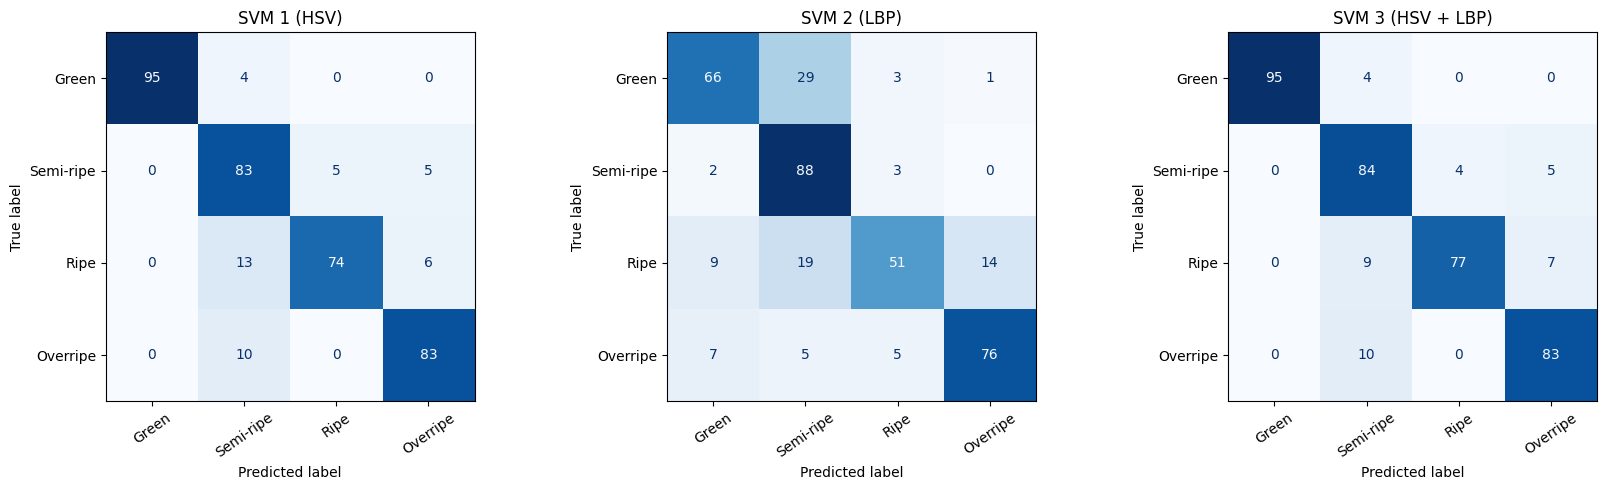

In [18]:
# Confusion Matrix cho cả 3 bộ đặc trưng
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (name, (X_tr, X_va, X_te)) in zip(axes, experiments.items()):
    model = trained_models[name]["model"]
    y_pred = model.predict(X_te)
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, labels=label_ids, display_labels=class_names,
        cmap="Blues", ax=ax, colorbar=False
    )
    ax.set_title(name)
    ax.tick_params(axis="x", labelrotation=35)

plt.tight_layout()
plt.show()

# **5. Xuất kết quả để làm demo web**

File `result.zip` có 3 mô hình SVM, hàm trích xuất đặc trưng, hàm dự đoán, cấu hình nhãn và bảng kết quả. Sau khi chạy notebook trên Kaggle, tải `result.zip` trong mục **Output**.

In [19]:
import os
import json
import joblib
import zipfile

os.makedirs("result/models", exist_ok=True)
os.makedirs("result/preprocessing", exist_ok=True)
os.makedirs("result/metrics", exist_ok=True)

# 1. Lưu các mô hình đã chọn bằng tập Validation
model_map = {
    "SVM 1 (HSV)": "svm_hsv.joblib",
    "SVM 2 (LBP)": "svm_lbp.joblib",
    "SVM 3 (HSV + LBP)": "svm_hsv_lbp.joblib"
}

for name, filename in model_map.items():
    joblib.dump(trained_models[name]["model"], "result/models/" + filename)

# 2. Lưu thông tin xử lý ảnh, bộ đặc trưng và nhãn
config = {
    "image_size": [128, 128],
    "resize": "keep_aspect_bilinear_center_letterbox",
    "padding": "black; excluded from HSV/LBP features",
    "color_format": "BGR",
    "label_map": {str(label_id): label for label_id, label in zip(label_ids, class_names)},
    "features": {"hsv": 128, "lbp": 10, "hsv_lbp": 138},
    "models": {"hsv": "svm_hsv.joblib", "lbp": "svm_lbp.joblib", "hsv_lbp": "svm_hsv_lbp.joblib"}
}
with open("result/preprocessing/config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, indent=4, ensure_ascii=False)

# 3. Lưu bảng đánh giá
df_results.to_csv("result/metrics/comparison.csv", index=False)
df_validation.to_csv("result/metrics/validation_grid.csv", index=False)

# 4. Lưu hàm rút trích đặc trưng (giống hệt hàm đã dùng khi train)
feature_code = 'import cv2\nimport numpy as np\nfrom skimage.feature import local_binary_pattern\n\ndef _valid_roi(image, valid_mask=None):\n    if valid_mask is None: return image\n    ys, xs = np.where(valid_mask > 0)\n    if not len(xs) or not len(ys): raise ValueError("Mask ảnh hợp lệ rỗng")\n    return image[ys.min():ys.max()+1, xs.min():xs.max()+1]\n\ndef resize_with_pad_bgr(image, img_size=(128, 128)):\n    target_h, target_w = img_size\n    height, width = image.shape[:2]\n    scale = min(target_w / width, target_h / height)\n    resized_w = max(1, min(target_w, int(round(width * scale))))\n    resized_h = max(1, min(target_h, int(round(height * scale))))\n    resized = cv2.resize(image, (resized_w, resized_h), interpolation=cv2.INTER_LINEAR)\n    left, top = (target_w-resized_w)//2, (target_h-resized_h)//2\n    right, bottom = target_w-resized_w-left, target_h-resized_h-top\n    padded = cv2.copyMakeBorder(resized, top, bottom, left, right, cv2.BORDER_CONSTANT, value=(0,0,0))\n    mask = np.zeros((target_h,target_w), dtype=np.uint8)\n    mask[top:top+resized_h, left:left+resized_w] = 255\n    return padded, mask\n\ndef extract_hsv(image, valid_mask=None, h_bins=16, s_bins=8):\n    hsv=cv2.cvtColor(image, cv2.COLOR_BGR2HSV)\n    hist=cv2.calcHist([hsv],[0,1],valid_mask,[h_bins,s_bins],[0,180,0,256])\n    return cv2.normalize(hist,hist).flatten().astype(np.float32)\n\ndef extract_lbp(image, valid_mask=None, P=8, R=1):\n    roi=_valid_roi(image,valid_mask)\n    gray=cv2.cvtColor(roi,cv2.COLOR_BGR2GRAY)\n    lbp=local_binary_pattern(gray,P=P,R=R,method="uniform")\n    n_bins=P+2\n    hist,_=np.histogram(lbp.ravel(),bins=n_bins,range=(0,n_bins),density=True)\n    return hist.astype(np.float32)\n\ndef extract_features(image, feature_name, valid_mask=None):\n    if feature_name=="hsv": return extract_hsv(image,valid_mask)\n    if feature_name=="lbp": return extract_lbp(image,valid_mask)\n    if feature_name=="hsv_lbp": return np.hstack([extract_hsv(image,valid_mask),extract_lbp(image,valid_mask)])\n    raise ValueError("Bộ đặc trưng không hợp lệ: "+str(feature_name))\n'
with open("result/preprocessing/feature_extraction.py", "w", encoding="utf-8") as f:
    f.write(feature_code)

# 5. Lưu hàm dự đoán để bạn làm web gọi trực tiếp
predict_code = 'import os\nimport json\nimport joblib\nimport cv2\nfrom preprocessing.feature_extraction import extract_features, resize_with_pad_bgr\n\nBASE_DIR = os.path.dirname(os.path.abspath(__file__))\n\n\ndef predict_image(image_path, feature_name="hsv_lbp"):\n    # Đọc thông tin cấu hình\n    with open(os.path.join(BASE_DIR, "preprocessing", "config.json"), encoding="utf-8") as f:\n        config = json.load(f)\n\n    if feature_name not in config["models"]:\n        raise ValueError("Chọn hsv, lbp hoặc hsv_lbp")\n\n    image = cv2.imread(image_path)  # BGR giống lúc train\n    if image is None:\n        raise ValueError("Không đọc được ảnh: " + str(image_path))\n\n    image, valid_mask = resize_with_pad_bgr(image, tuple(config["image_size"]))\n    features = extract_features(image, feature_name, valid_mask).reshape(1, -1)\n    model_path = os.path.join(BASE_DIR, "models", config["models"][feature_name])\n    model = joblib.load(model_path)\n    label_id = int(model.predict(features)[0])\n    label = config["label_map"][str(label_id)]\n    return label_id, label\n'
with open("result/predict.py", "w", encoding="utf-8") as f:
    f.write(predict_code)

with open("result/requirements.txt", "w", encoding="utf-8") as f:
    f.write("numpy\nopencv-python-headless\nscikit-image\nscikit-learn\njoblib\n")

with open("result/README.md", "w", encoding="utf-8") as f:
    f.write("# SVM dự đoán độ chín chuối\n\n"
            "Chọn feature: hsv, lbp, hsv_lbp.\n\n"
            "Cài: pip install -r requirements.txt\n\n"
            "Ví dụ: from predict import predict_image\n"
            "label_id, label = predict_image('banana.jpg', 'hsv_lbp')\n"
            "print(label_id, label)\n"
            "Chạy Python trong thư mục giải nén. Không có confidence.\n")

# 6. Nén toàn bộ thư mục result thành ZIP
zip_path = "/kaggle/working/result.zip" if os.path.isdir("/kaggle/working") else "result.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk("result"):
        for filename in files:
            path = os.path.join(root, filename)
            zipf.write(path, arcname=os.path.relpath(path, "result"))

print("Đã tạo:", zip_path)
print("Các file trong ZIP:")
with zipfile.ZipFile(zip_path) as zipf:
    print("\n".join(zipf.namelist()))

Đã tạo: /kaggle/working/result.zip
Các file trong ZIP:
README.md
requirements.txt
predict.py
metrics/comparison.csv
metrics/validation_grid.csv
models/svm_hsv.joblib
models/svm_lbp.joblib
models/svm_hsv_lbp.joblib
preprocessing/feature_extraction.py
preprocessing/config.json


**Lưu ý khi báo cáo:** Cần kiểm tra ảnh tăng cường (augmentation) có cùng ảnh gốc giữa các tập hay không. Notebook sử dụng split đã có trong CSV, chưa tự xác minh được điều này. Điểm Test chỉ dùng để báo cáo, không tiếp tục tinh chỉnh siêu tham số dựa trên Test.